In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, pairwise_distances
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram
from umap import UMAP

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_csv('german_credit_data.csv').drop(columns='Unnamed: 0')
data.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


In [3]:
data.shape

(1000, 9)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               1000 non-null   int64
 1   Sex               1000 non-null   str  
 2   Job               1000 non-null   int64
 3   Housing           1000 non-null   str  
 4   Saving accounts   817 non-null    str  
 5   Checking account  606 non-null    str  
 6   Credit amount     1000 non-null   int64
 7   Duration          1000 non-null   int64
 8   Purpose           1000 non-null   str  
dtypes: int64(4), str(5)
memory usage: 70.4 KB


In [5]:
data.describe()

,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [6]:
data.isnull().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

In [7]:
data.duplicated().sum()

np.int64(0)

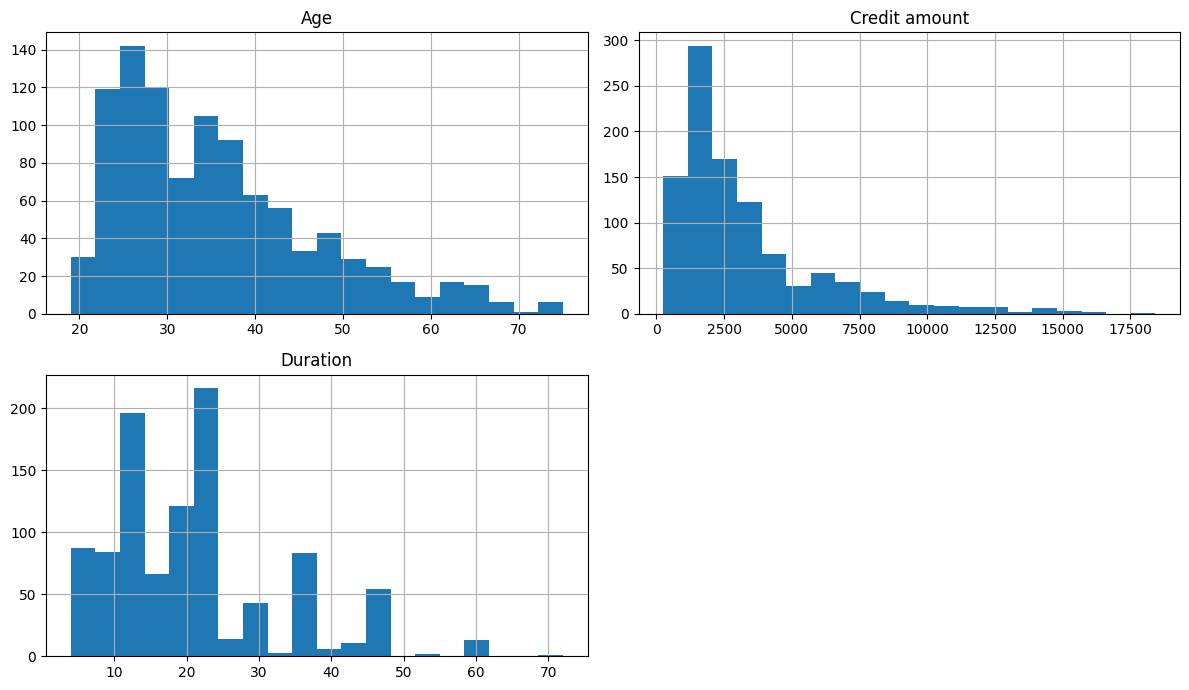

In [8]:
num_cols = ['Age', 'Credit amount', 'Duration']
cat_cols = ['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

data[num_cols].hist(figsize=(12, 7), bins=20)
plt.tight_layout()
plt.show()

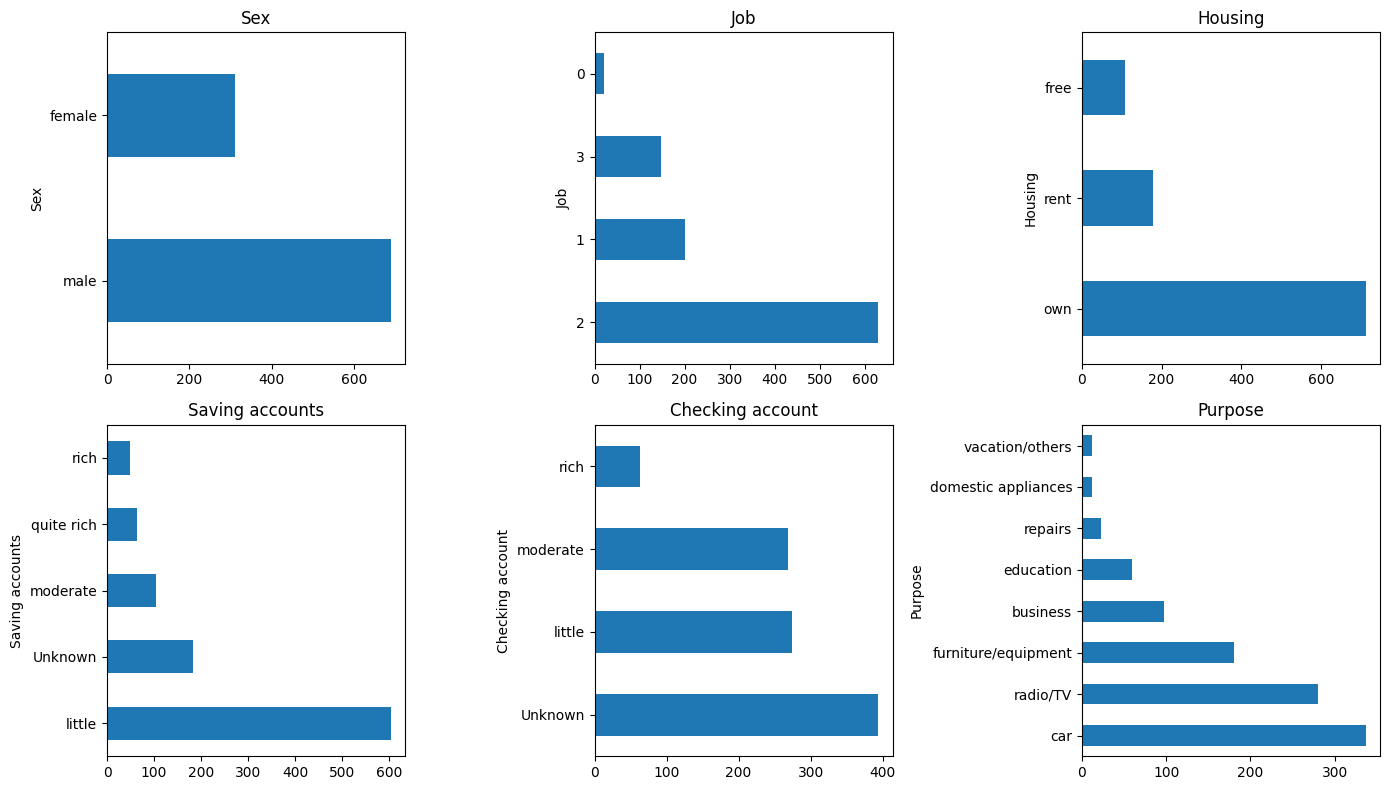

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, cat_cols):
    data[col].fillna('Unknown').value_counts().plot.barh(ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

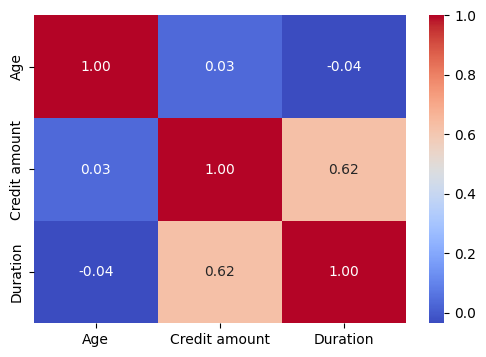

In [10]:
plt.figure(figsize=(6, 4))
sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [11]:
df = data.copy()
df[cat_cols] = df[cat_cols].astype('string').fillna('Unknown')
features = pd.get_dummies(df, columns=cat_cols, dtype=float)

features[['Credit amount', 'Duration']] = np.log1p(features[['Credit amount', 'Duration']])

# Без масштабирования сумма кредита будет определять расстояния между клиентами.
features[num_cols] = StandardScaler().fit_transform(features[num_cols])

# Несовпадение категорий и разница в одно стандартное отклонение имеют одинаковый вес.
dummy_cols = features.columns.difference(num_cols)
features[dummy_cols] = features[dummy_cols] / np.sqrt(2)

X = features.to_numpy()
D = pairwise_distances(X)
np.fill_diagonal(D, 0)
features.head()

,Age,Credit amount,Duration,Sex_female,Sex_male,Job_0,Job_1,Job_2,Job_3,Housing_free,...,Checking account_moderate,Checking account_rich,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,2.766456,-0.933992,-1.822056,0.000000,0.707107,0.0,0.000000,0.707107,0.0,0.000000,...,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.707107,0.0,0.0
1,-1.191404,1.163149,1.741206,0.707107,0.000000,0.0,0.000000,0.707107,0.0,0.000000,...,0.707107,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.707107,0.0,0.0
2,1.183312,-0.181750,-0.688500,0.000000,0.707107,0.0,0.707107,0.000000,0.0,0.000000,...,0.000000,0.0,0.0,0.000000,0.0,0.707107,0.000000,0.000000,0.0,0.0
3,0.831502,1.525385,1.502020,0.000000,0.707107,0.0,0.000000,0.707107,0.0,0.707107,...,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.707107,0.000000,0.0,0.0
4,1.535122,0.904761,0.508940,0.000000,0.707107,0.0,0.000000,0.707107,0.0,0.707107,...,0.000000,0.0,0.0,0.707107,0.0,0.000000,0.000000,0.000000,0.0,0.0


In [12]:
# K-means
k_values = range(2, 11)
kmeans_labels = {}
rows = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=30, random_state=42)
    labels = model.fit_predict(X)
    kmeans_labels[k] = labels
    rows.append([k, model.inertia_, silhouette_score(D, labels, metric='precomputed')])

kmeans_results = pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette'])
kmeans_results

,k,inertia,silhouette
0,2,3618.004967,0.199951
1,3,3104.048029,0.191511
2,4,2850.173033,0.136971
3,5,2700.515796,0.125859
4,6,2593.828760,0.115417
5,7,2498.066564,0.111706
6,8,2419.475501,0.108231
7,9,2362.531834,0.093299
8,10,2309.043530,0.096155


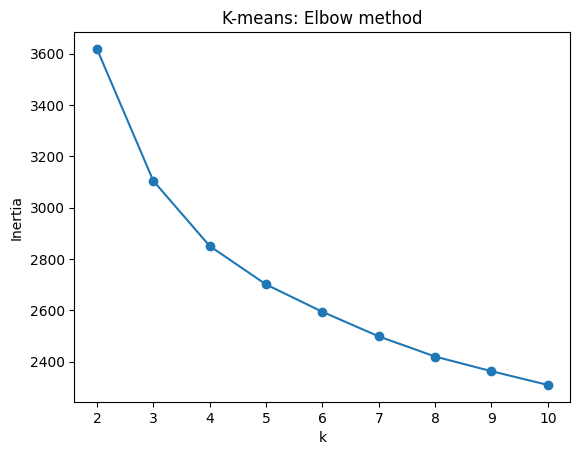

In [13]:
plt.plot(kmeans_results['k'], kmeans_results['inertia'], marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('K-means: Elbow method')
plt.show()

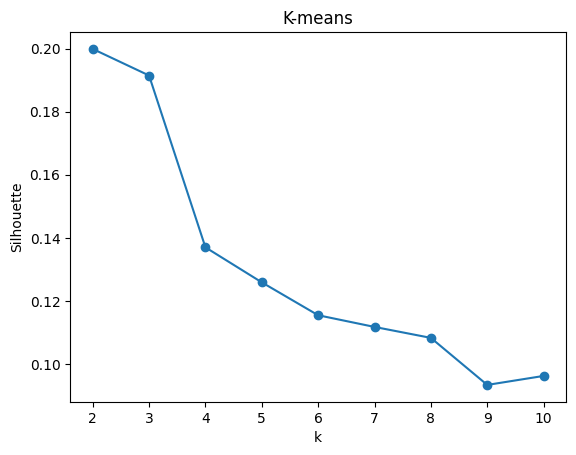

In [14]:
plt.plot(kmeans_results['k'], kmeans_results['silhouette'], marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette')
plt.title('K-means')
plt.show()

In [15]:
k_kmeans = int(kmeans_results.loc[kmeans_results['silhouette'].idxmax(), 'k'])
labels_kmeans = kmeans_labels[k_kmeans]
print('K-means, k =', k_kmeans)
pd.Series(labels_kmeans).value_counts().sort_index()

K-means, k = 2


0    461
1    539
Name: count, dtype: int64

In [16]:
# Иерархическая кластеризация
ward_labels = {}
rows = []

for k in k_values:
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    ward_labels[k] = labels
    inertia = sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum()
                  for c in np.unique(labels))
    rows.append([k, inertia, silhouette_score(D, labels, metric='precomputed')])

ward_results = pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette'])
ward_results

,k,inertia,silhouette
0,2,3847.806311,0.155707
1,3,3302.030622,0.163794
2,4,3068.022772,0.103070
3,5,2901.304543,0.084608
4,6,2818.956227,0.069897
5,7,2741.632729,0.062873
6,8,2665.437925,0.056633
7,9,2601.284067,0.058316
8,10,2537.291846,0.053435


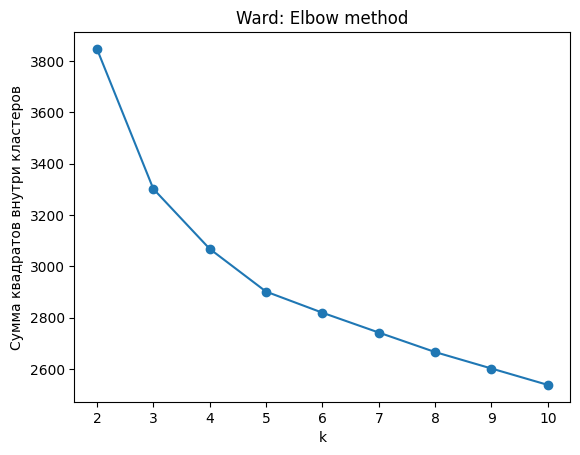

In [17]:
plt.plot(ward_results['k'], ward_results['inertia'], marker='o')
plt.xlabel('k')
plt.ylabel('Сумма квадратов внутри кластеров')
plt.title('Ward: Elbow method')
plt.show()

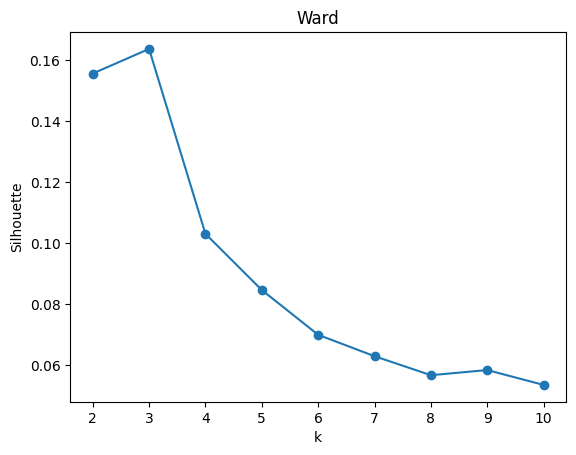

In [18]:
plt.plot(ward_results['k'], ward_results['silhouette'], marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette')
plt.title('Ward')
plt.show()

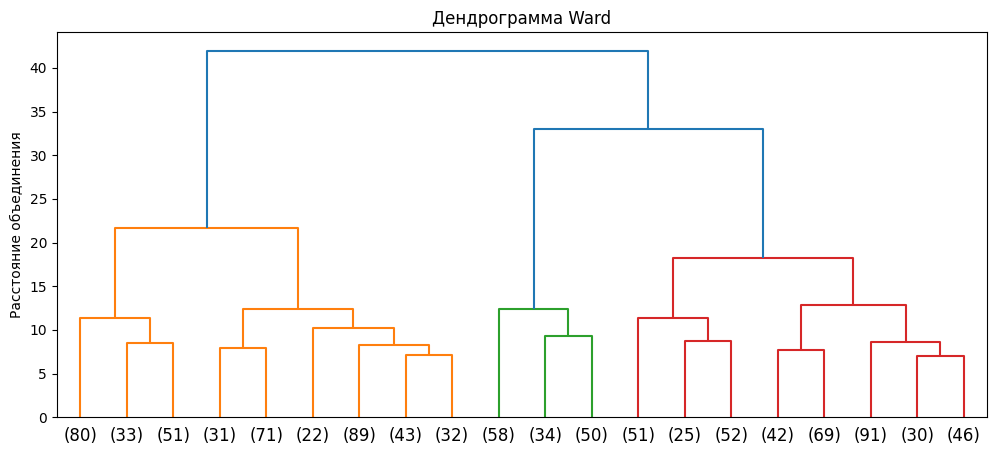

In [19]:
plt.figure(figsize=(12, 5))
dendrogram(linkage(X, method='ward'), truncate_mode='lastp', p=20)
plt.title('Дендрограмма Ward')
plt.ylabel('Расстояние объединения')
plt.show()

In [20]:
k_ward = int(ward_results.loc[ward_results['silhouette'].idxmax(), 'k'])
labels_ward = ward_labels[k_ward]
print('Ward, k =', k_ward)
pd.Series(labels_ward).value_counts().sort_index()

Ward, k = 3


0    452
1    406
2    142
Name: count, dtype: int64

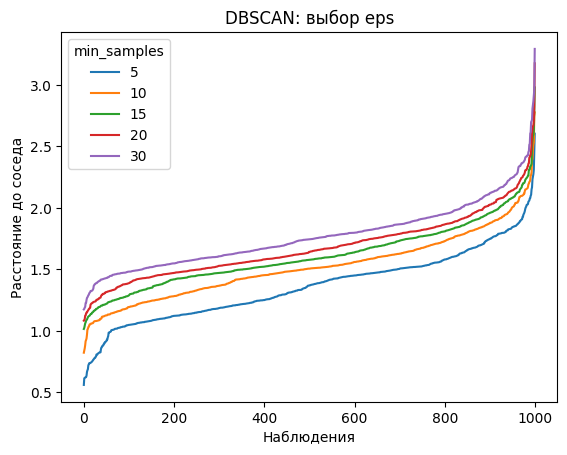

In [ ]:
sorted_distances = np.sort(D, axis=1)
for min_samples in [5, 10, 15, 20, 30]:
    plt.plot(np.sort(sorted_distances[:, min_samples - 1]), label=f'{min_samples}')
plt.xlabel('Наблюдения')
plt.ylabel('Расстояние до соседа')
plt.title('DBSCAN: выбор eps')
plt.legend(title='min_samples')
plt.show()

In [22]:
rows = []
for min_samples in [5, 10, 15, 20, 30]:
    for eps in np.round(np.arange(.5, 3.51, .05), 2):
        labels = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed').fit_predict(D)
        mask = labels != -1
        sizes = pd.Series(labels[mask]).value_counts()
        score = np.nan
        if 2 <= len(sizes) < mask.sum():
            score = silhouette_score(D[np.ix_(mask, mask)], labels[mask], metric='precomputed')
        rows.append([eps, min_samples, len(sizes), 1 - mask.mean(),
                     sizes.min() if len(sizes) else 0,
                     sizes.max() / mask.sum() if len(sizes) else np.nan, score])

dbscan_results = pd.DataFrame(rows, columns=[
    'eps', 'min_samples', 'clusters', 'noise', 'min_size', 'largest_share', 'silhouette'
])
dbscan_results.sort_values('silhouette', ascending=False).head(10)

,eps,min_samples,clusters,noise,min_size,largest_share,silhouette
3,0.65,5,3,0.977,5,0.391304,0.615364
4,0.70,5,4,0.970,5,0.333333,0.475892
5,0.75,5,5,0.956,5,0.363636,0.460796
6,0.80,5,8,0.938,5,0.258065,0.400006
7,0.85,5,9,0.924,5,0.236842,0.345021
8,0.90,5,10,0.909,5,0.241758,0.310928
9,0.95,5,11,0.899,5,0.217822,0.289622
72,1.05,10,4,0.939,7,0.557377,0.285651
10,1.00,5,11,0.895,5,0.228571,0.264071
135,1.15,15,2,0.881,21,0.823529,0.235252


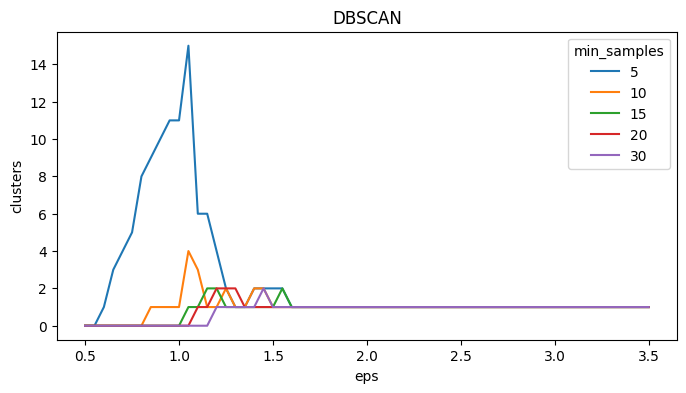

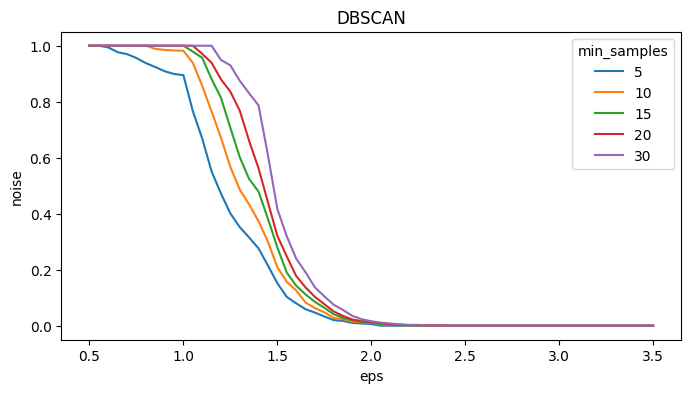

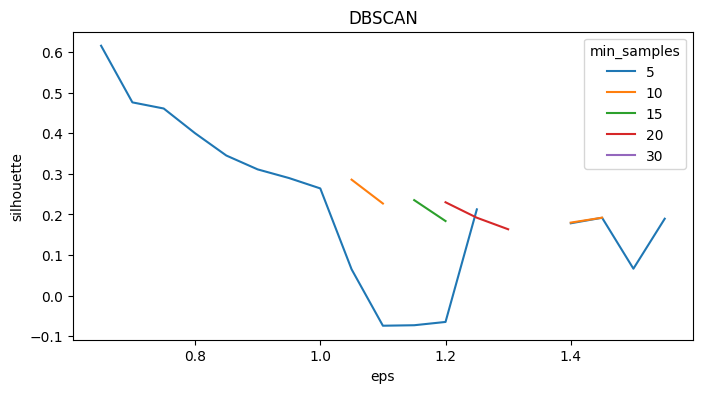

In [23]:
for column in ['clusters', 'noise', 'silhouette']:
    plt.figure(figsize=(8, 4))
    for min_samples, group in dbscan_results.groupby('min_samples'):
        plt.plot(group['eps'], group[column], label=f'{min_samples}')
    plt.xlabel('eps')
    plt.ylabel(column)
    plt.title('DBSCAN')
    plt.legend(title='min_samples')
    plt.show()

In [ ]:
candidates = dbscan_results.query('2 <= clusters <= 10 and min_size >= 20 and largest_share <= .9').copy()
candidates['score'] = candidates['silhouette'] * (1 - candidates['noise'])
best_dbscan = candidates.sort_values('score', ascending=False).iloc[0]

dbscan = DBSCAN(eps=float(best_dbscan['eps']), min_samples=int(best_dbscan['min_samples']),
                metric='precomputed')
labels_dbscan = dbscan.fit_predict(D)
best_dbscan

eps               1.300000
min_samples      20.000000
clusters          2.000000
noise             0.768000
min_size         39.000000
largest_share     0.831897
silhouette        0.163501
score             0.037932
Name: 199, dtype: float64

In [25]:
clusters = {'K-means': labels_kmeans, 'Ward': labels_ward, 'DBSCAN': labels_dbscan}
rows = []

for name, labels in clusters.items():
    mask = labels != -1
    rows.append([name, len(np.unique(labels[mask])), (labels == -1).mean(),
                 silhouette_score(D[np.ix_(mask, mask)], labels[mask], metric='precomputed')])

pd.DataFrame(rows, columns=['method', 'clusters', 'noise', 'silhouette'])

,method,clusters,noise,silhouette
0,K-means,2,0.000,0.199951
1,Ward,3,0.000,0.163794
2,DBSCAN,2,0.768,0.163501


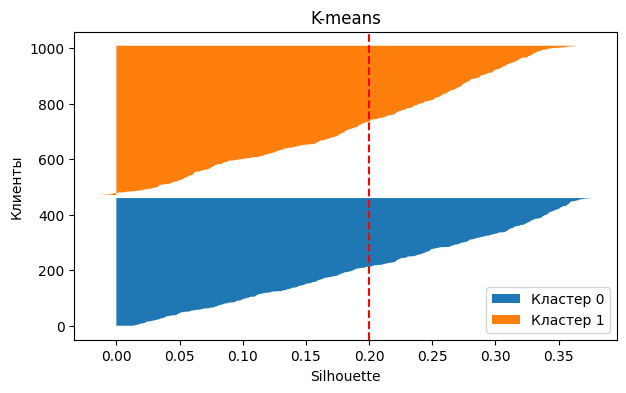

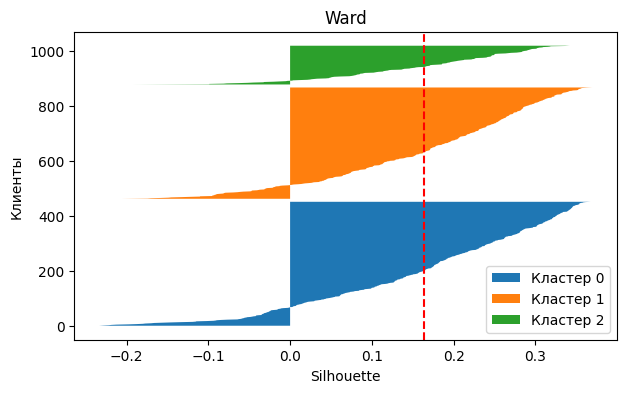

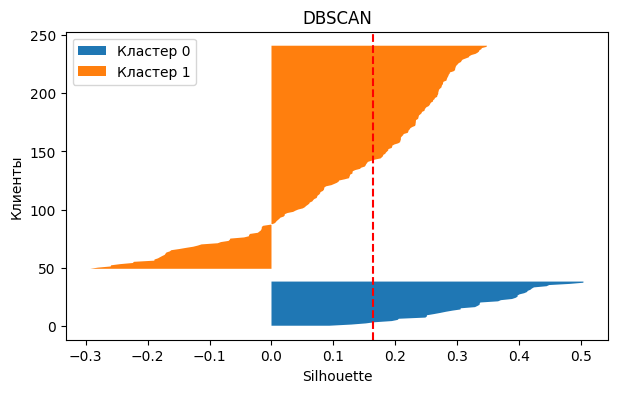

In [ ]:
# Silhouette plots. Шум DBSCAN не включаем
for name, labels in clusters.items():
    mask = labels != -1
    scores = silhouette_samples(D[np.ix_(mask, mask)], labels[mask], metric='precomputed')
    plt.figure(figsize=(7, 4))
    bottom = 0
    for cluster in np.unique(labels[mask]):
        values = np.sort(scores[labels[mask] == cluster])
        plt.fill_betweenx(np.arange(bottom, bottom + len(values)), 0, values,
                          label=f'Кластер {cluster}')
        bottom += len(values) + 10
    plt.axvline(scores.mean(), color='red', linestyle='--')
    plt.xlabel('Silhouette')
    plt.ylabel('Клиенты')
    plt.title(name)
    plt.legend()
    plt.show()

In [27]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
X_umap = UMAP(n_components=2, n_neighbors=30, min_dist=.15, random_state=42, n_jobs=1).fit_transform(X)
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=1).fit_transform(X)

print('PCA: доля сохранённой дисперсии =', round(pca.explained_variance_ratio_.sum(), 3))

PCA: доля сохранённой дисперсии = 0.566


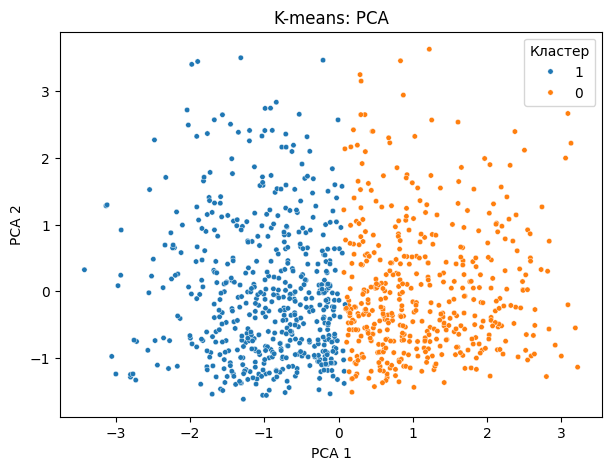

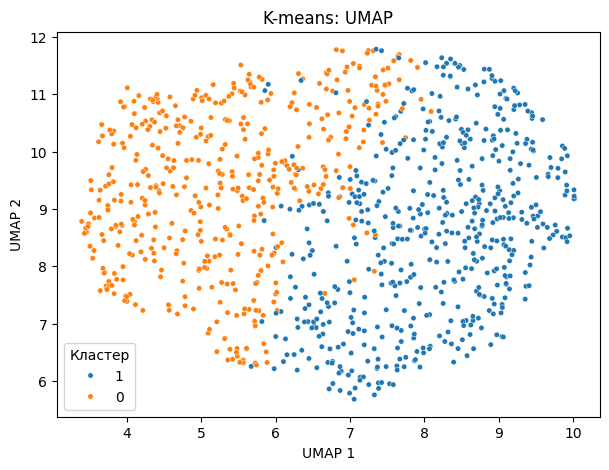

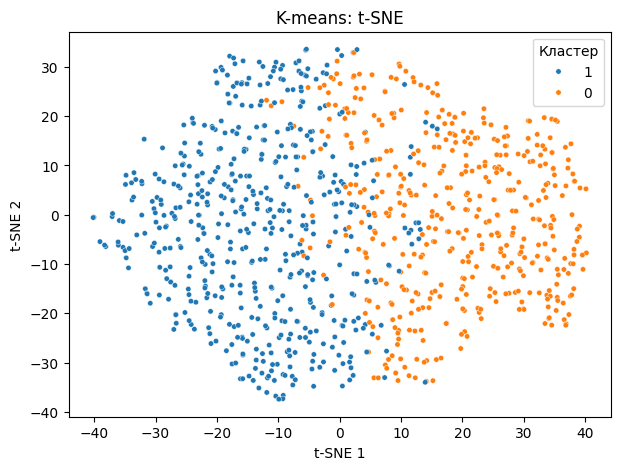

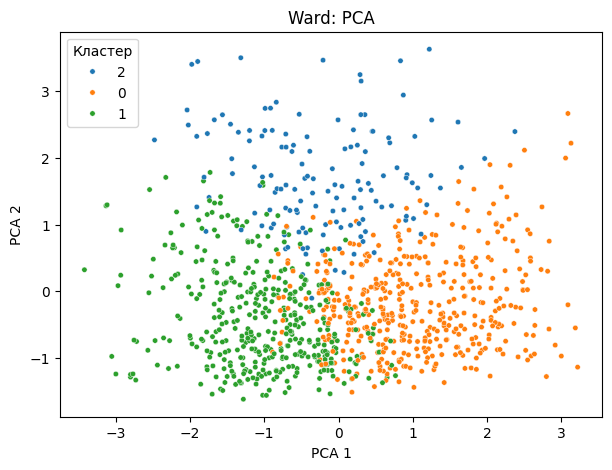

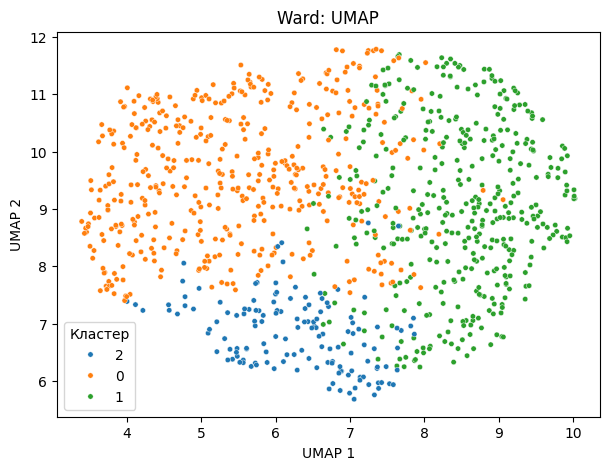

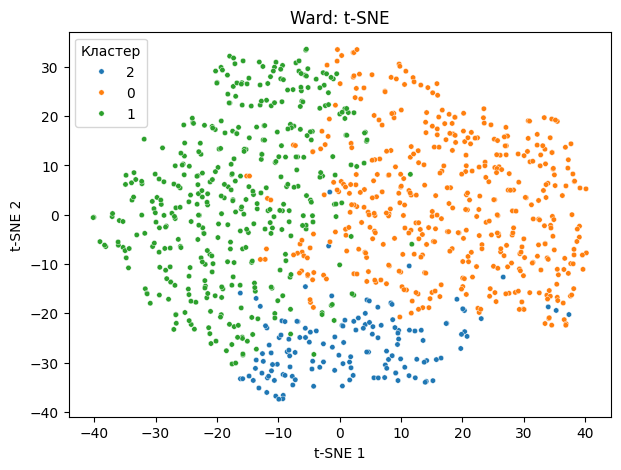

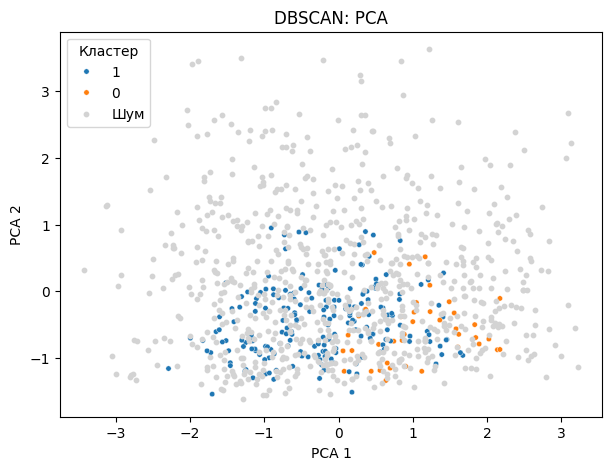

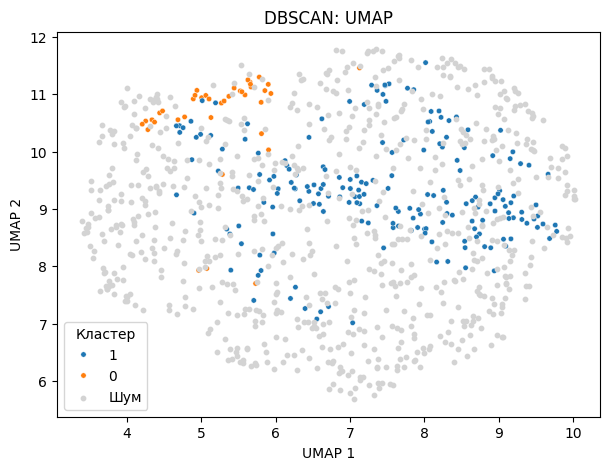

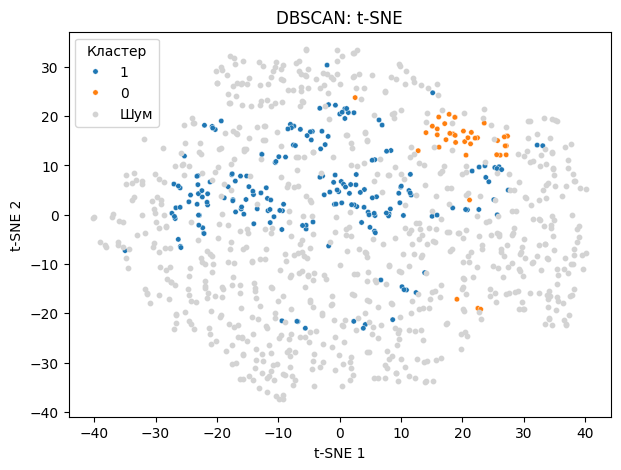

In [28]:
projections = {'PCA': X_pca, 'UMAP': X_umap, 't-SNE': X_tsne}

for name, labels in clusters.items():
    for projection, values in projections.items():
        plt.figure(figsize=(7, 5))
        mask = labels != -1
        sns.scatterplot(x=values[mask, 0], y=values[mask, 1], hue=labels[mask].astype(str),
                        palette='tab10', s=15)
        if (~mask).any():
            plt.scatter(values[~mask, 0], values[~mask, 1], c='lightgray', s=10, label='Шум')
        plt.title(f'{name}: {projection}')
        plt.xlabel(f'{projection} 1')
        plt.ylabel(f'{projection} 2')
        plt.legend(title='Кластер')
        plt.show()

In [29]:
for name, labels in clusters.items():
    print(name)
    display(pd.Series(labels, name='cluster').value_counts().sort_index())
    display(df.assign(cluster=labels).groupby('cluster')[num_cols].agg(['mean', 'median']).round(1))

K-means


cluster
0    461
1    539
Name: count, dtype: int64

Age        Credit amount         Duration       
         mean median          mean  median     mean median
cluster                                                   
0        35.3   33.0        5231.2  4165.0     30.1   24.0
1        35.8   33.0        1595.0  1409.0     13.0   12.0

Ward


cluster
0    452
1    406
2    142
Name: count, dtype: int64

Age        Credit amount         Duration       
         mean median          mean  median     mean median
cluster                                                   
0        33.0   32.0        4988.5  3954.0     29.2   24.0
1        31.5   29.0        1544.5  1353.5     12.6   12.0
2        55.1   54.0        2742.1  2172.5     18.2   18.0

DBSCAN


cluster
-1    768
 0     39
 1    193
Name: count, dtype: int64

Age        Credit amount         Duration       
         mean median          mean  median     mean median
cluster                                                   
-1       37.2   35.0        3486.9  2330.0     21.0   18.0
 0       28.6   28.0        4336.8  3965.0     29.6   30.0
 1       30.5   30.0        2197.7  1934.0     18.6   18.0

In [30]:
# Средние индикаторов категорий — их доли в кластере.
profile = pd.get_dummies(df, columns=cat_cols, dtype=float)
for name, labels in clusters.items():
    print(name)
    display(profile.assign(cluster=labels).groupby('cluster').mean().round(2).T)
    display(df.assign(cluster=labels).groupby('cluster')[cat_cols].agg(lambda x: x.mode().iloc[0]))

K-means


cluster,0,1
Age,35.27,35.78
Credit amount,5231.16,1594.98
Duration,30.10,13.04
Sex_female,0.25,0.36
Sex_male,0.75,0.64
Job_0,0.02,0.03
Job_1,0.11,0.28
Job_2,0.65,0.61
Job_3,0.22,0.08
Housing_free,0.15,0.07


,Sex,Job,Housing,Saving accounts,Checking account,Purpose
cluster,,,,,,
0,male,2,own,little,Unknown,car
1,male,2,own,little,Unknown,radio/TV


Ward


cluster,0,1,2
Age,33.04,31.51,55.08
Credit amount,4988.51,1544.52,2742.09
Duration,29.24,12.55,18.25
Sex_female,0.22,0.45,0.20
Sex_male,0.78,0.55,0.80
Job_0,0.02,0.02,0.04
Job_1,0.15,0.26,0.21
Job_2,0.61,0.66,0.61
Job_3,0.23,0.07,0.13
Housing_free,0.12,0.05,0.23


,Sex,Job,Housing,Saving accounts,Checking account,Purpose
cluster,,,,,,
0,male,2,own,little,Unknown,car
1,male,2,own,little,Unknown,car
2,male,2,own,little,Unknown,car


DBSCAN


cluster,-1,0,1
Age,37.17,28.62,30.49
Credit amount,3486.92,4336.85,2197.74
Duration,21.04,29.62,18.59
Sex_female,0.35,0.03,0.21
Sex_male,0.65,0.97,0.79
Job_0,0.03,0.03,0.00
Job_1,0.25,0.03,0.05
Job_2,0.55,0.92,0.91
Job_3,0.18,0.03,0.04
Housing_free,0.14,0.03,0.01


,Sex,Job,Housing,Saving accounts,Checking account,Purpose
cluster,,,,,,
-1,male,2,own,little,Unknown,car
0,male,2,own,little,little,furniture/equipment
1,male,2,own,little,Unknown,radio/TV


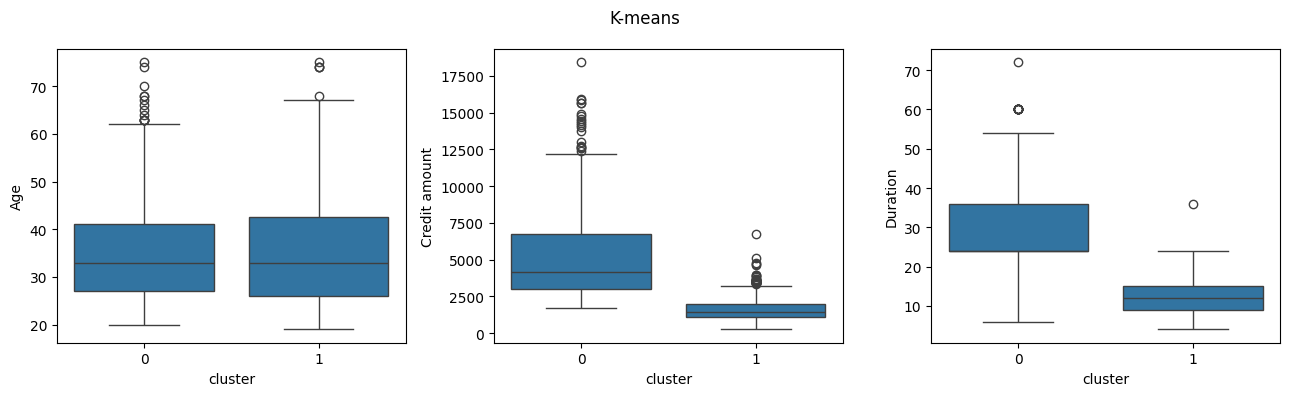

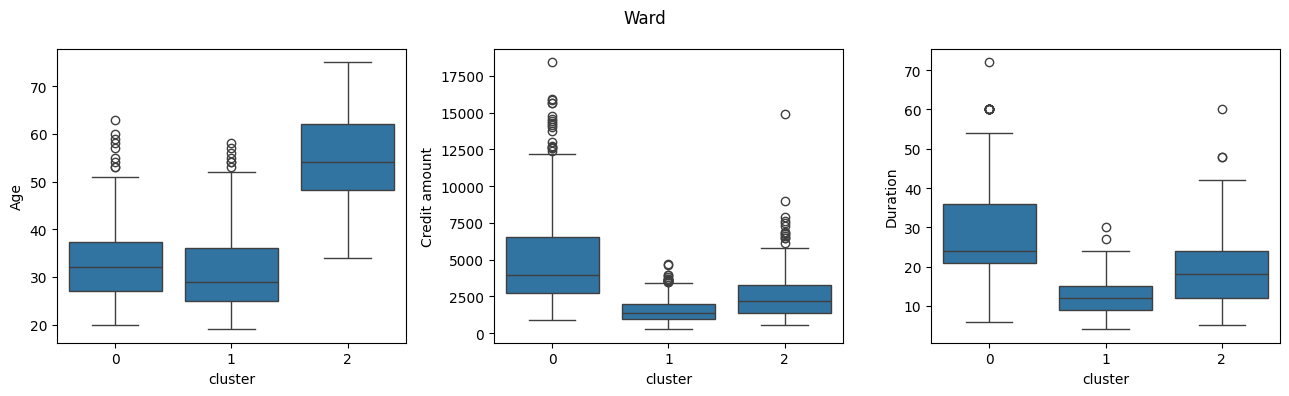

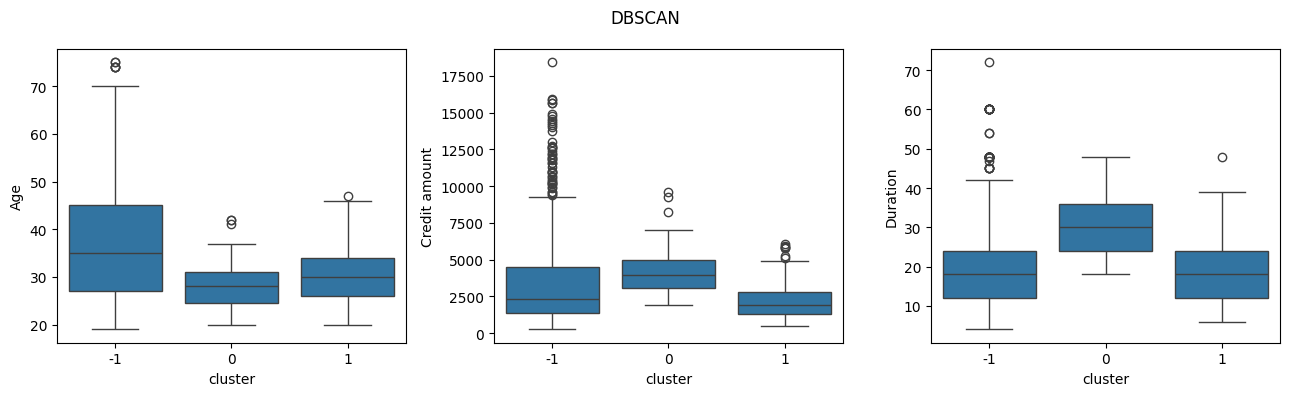

In [31]:
for name, labels in clusters.items():
    grouped = profile.assign(cluster=labels)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, col in zip(axes, num_cols):
        sns.boxplot(data=grouped, x='cluster', y=col, ax=ax)
    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

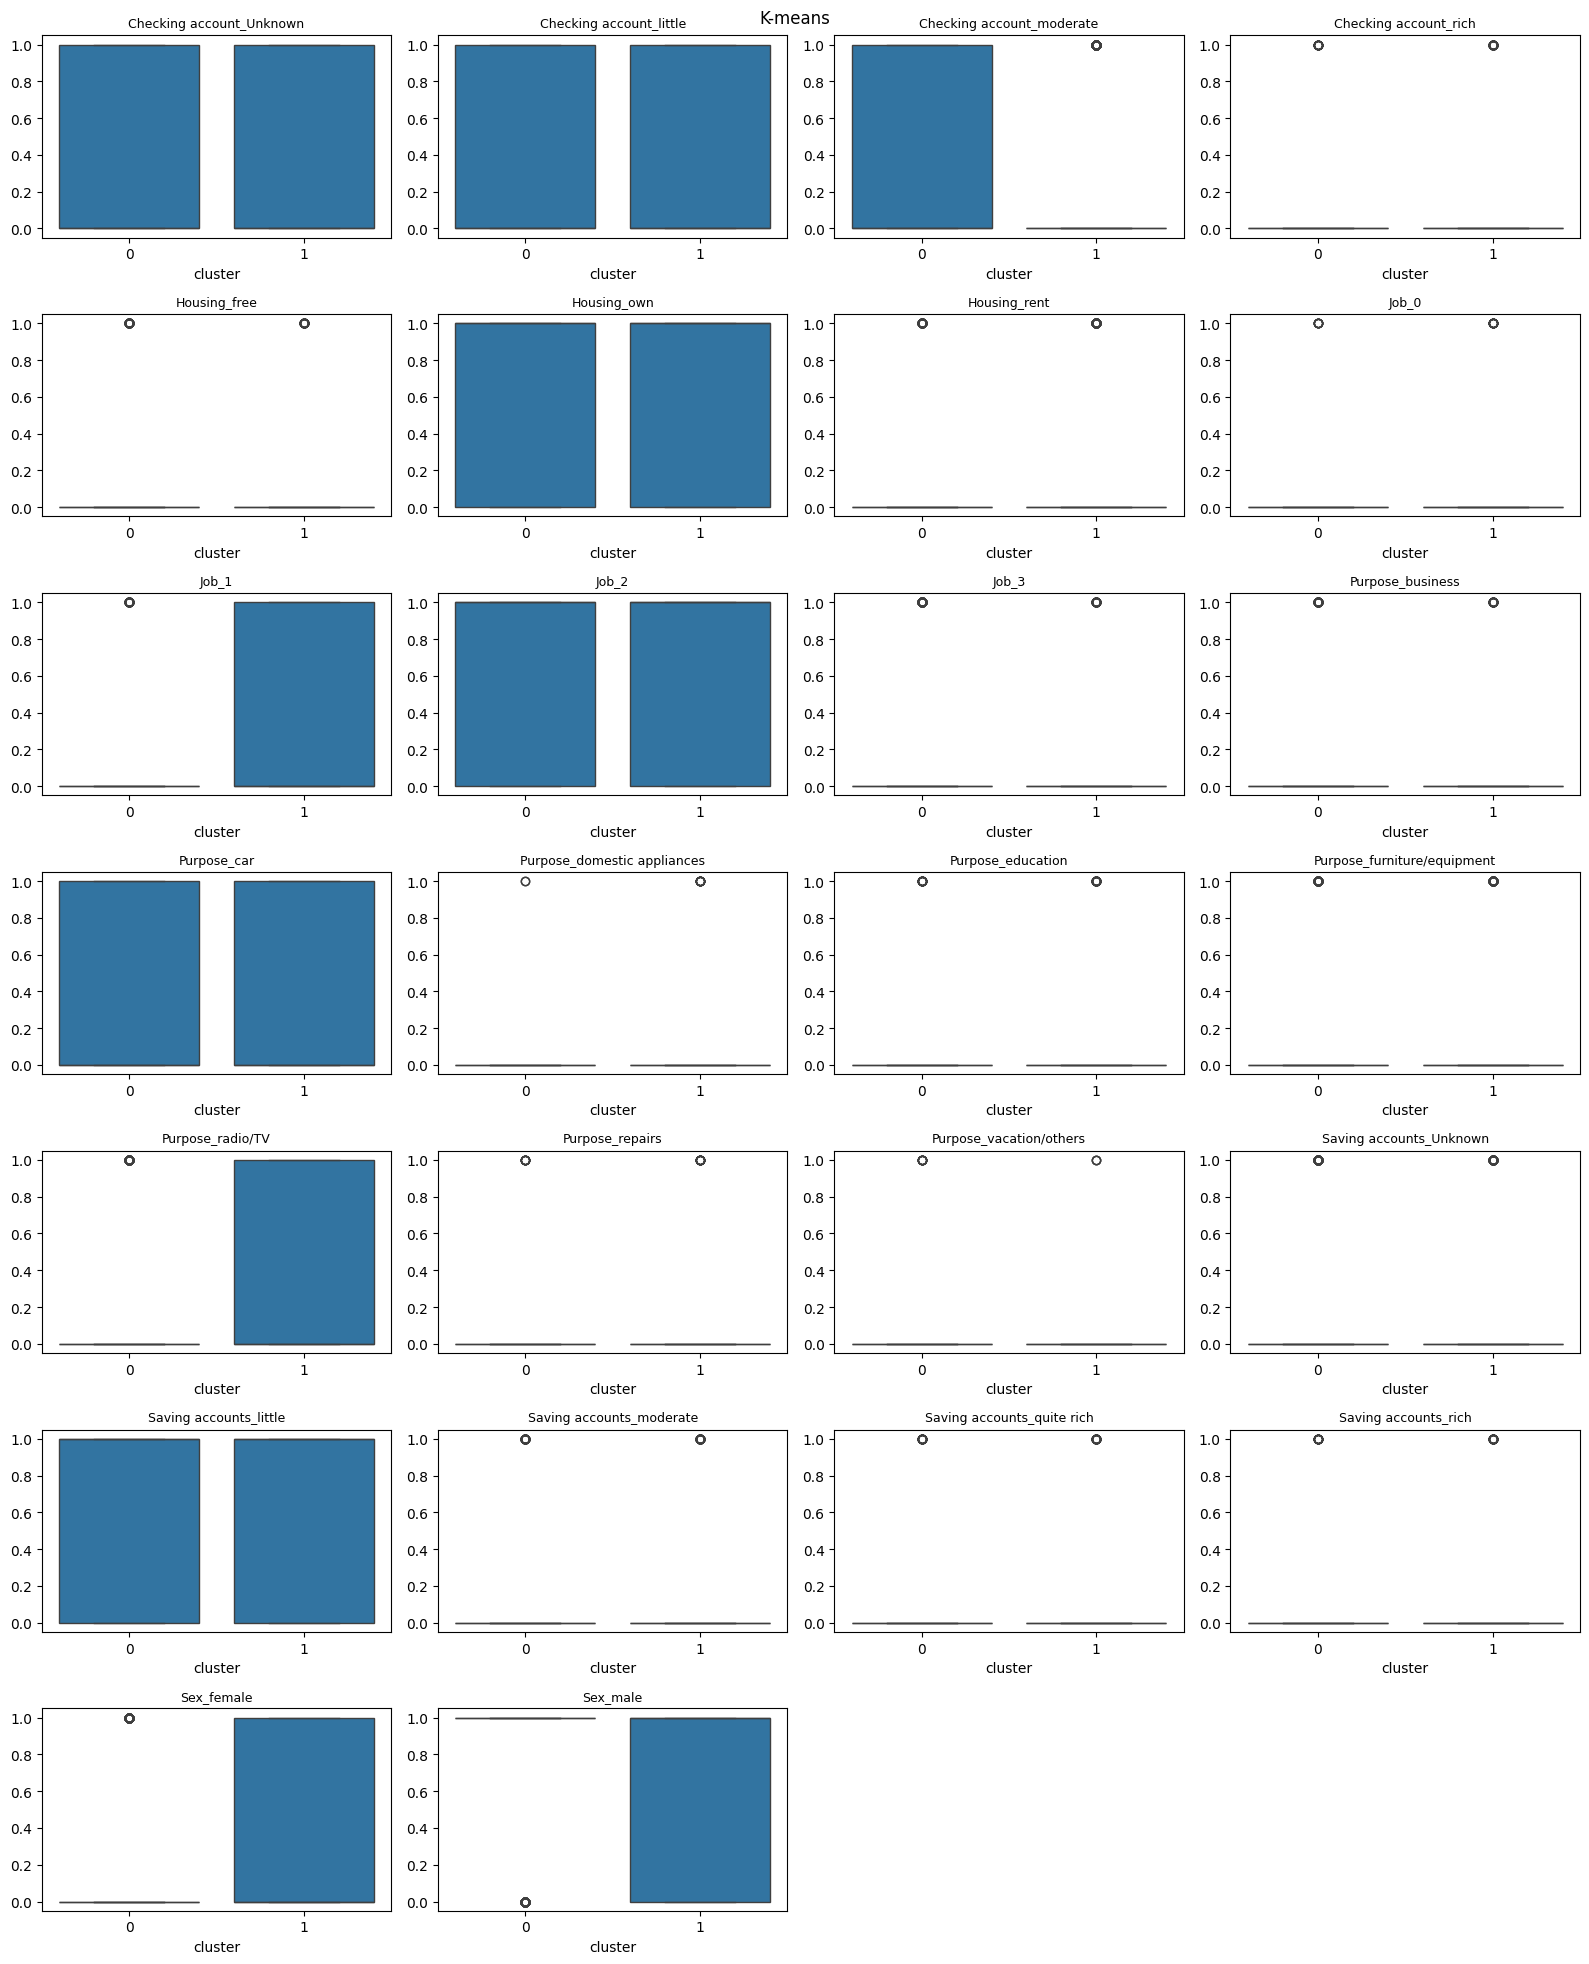

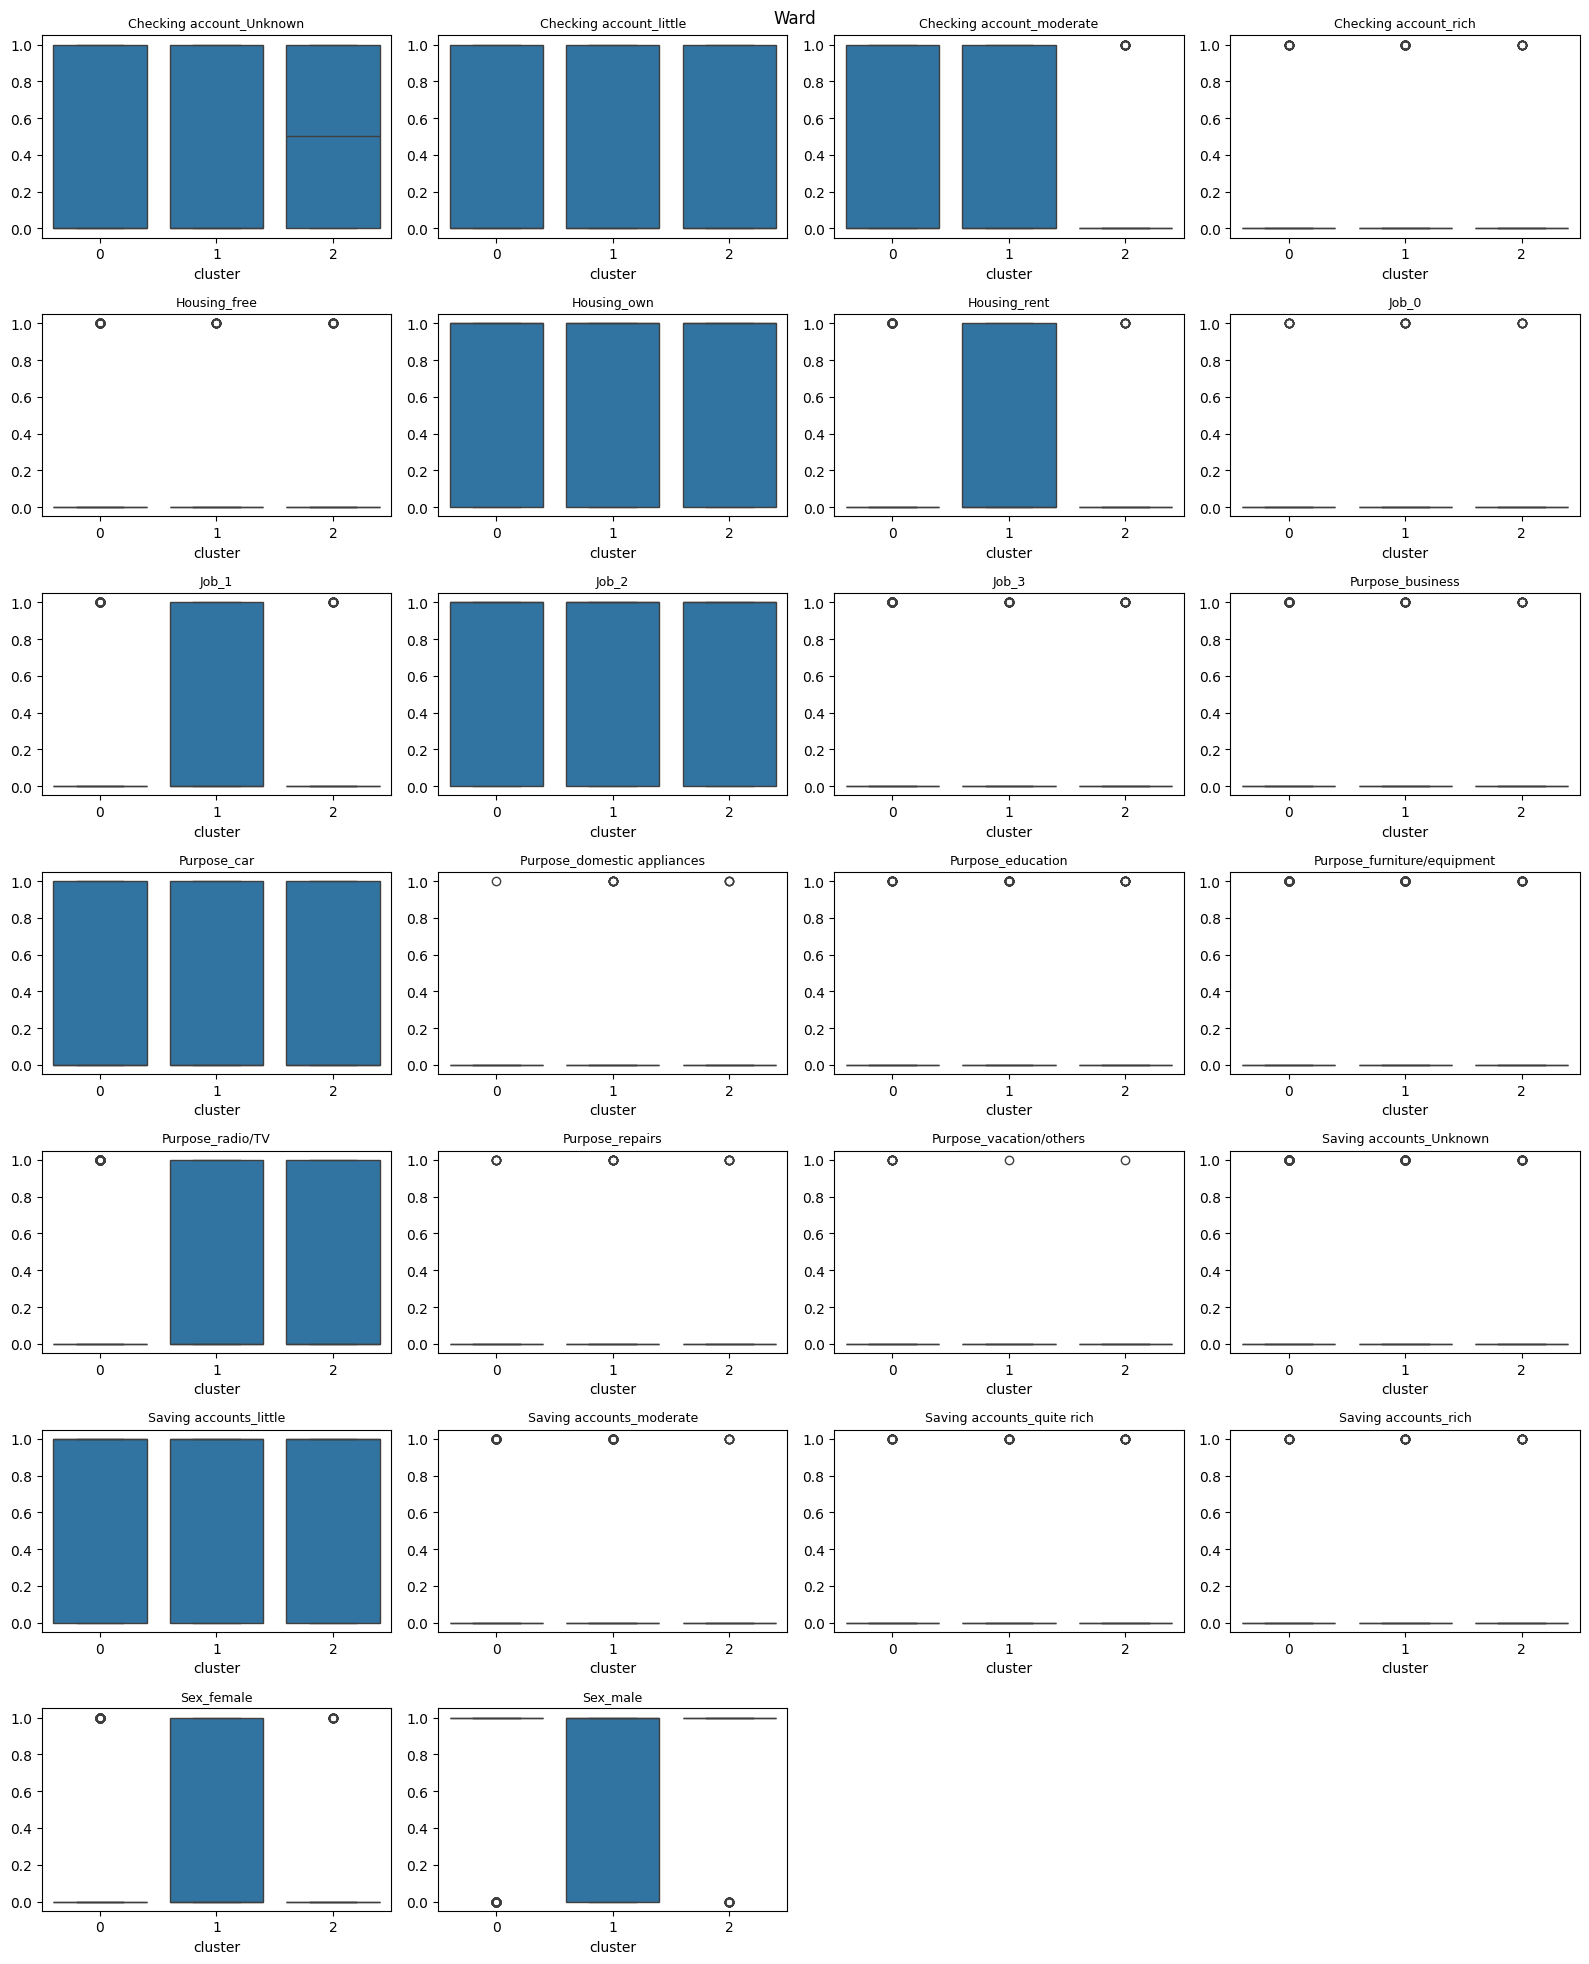

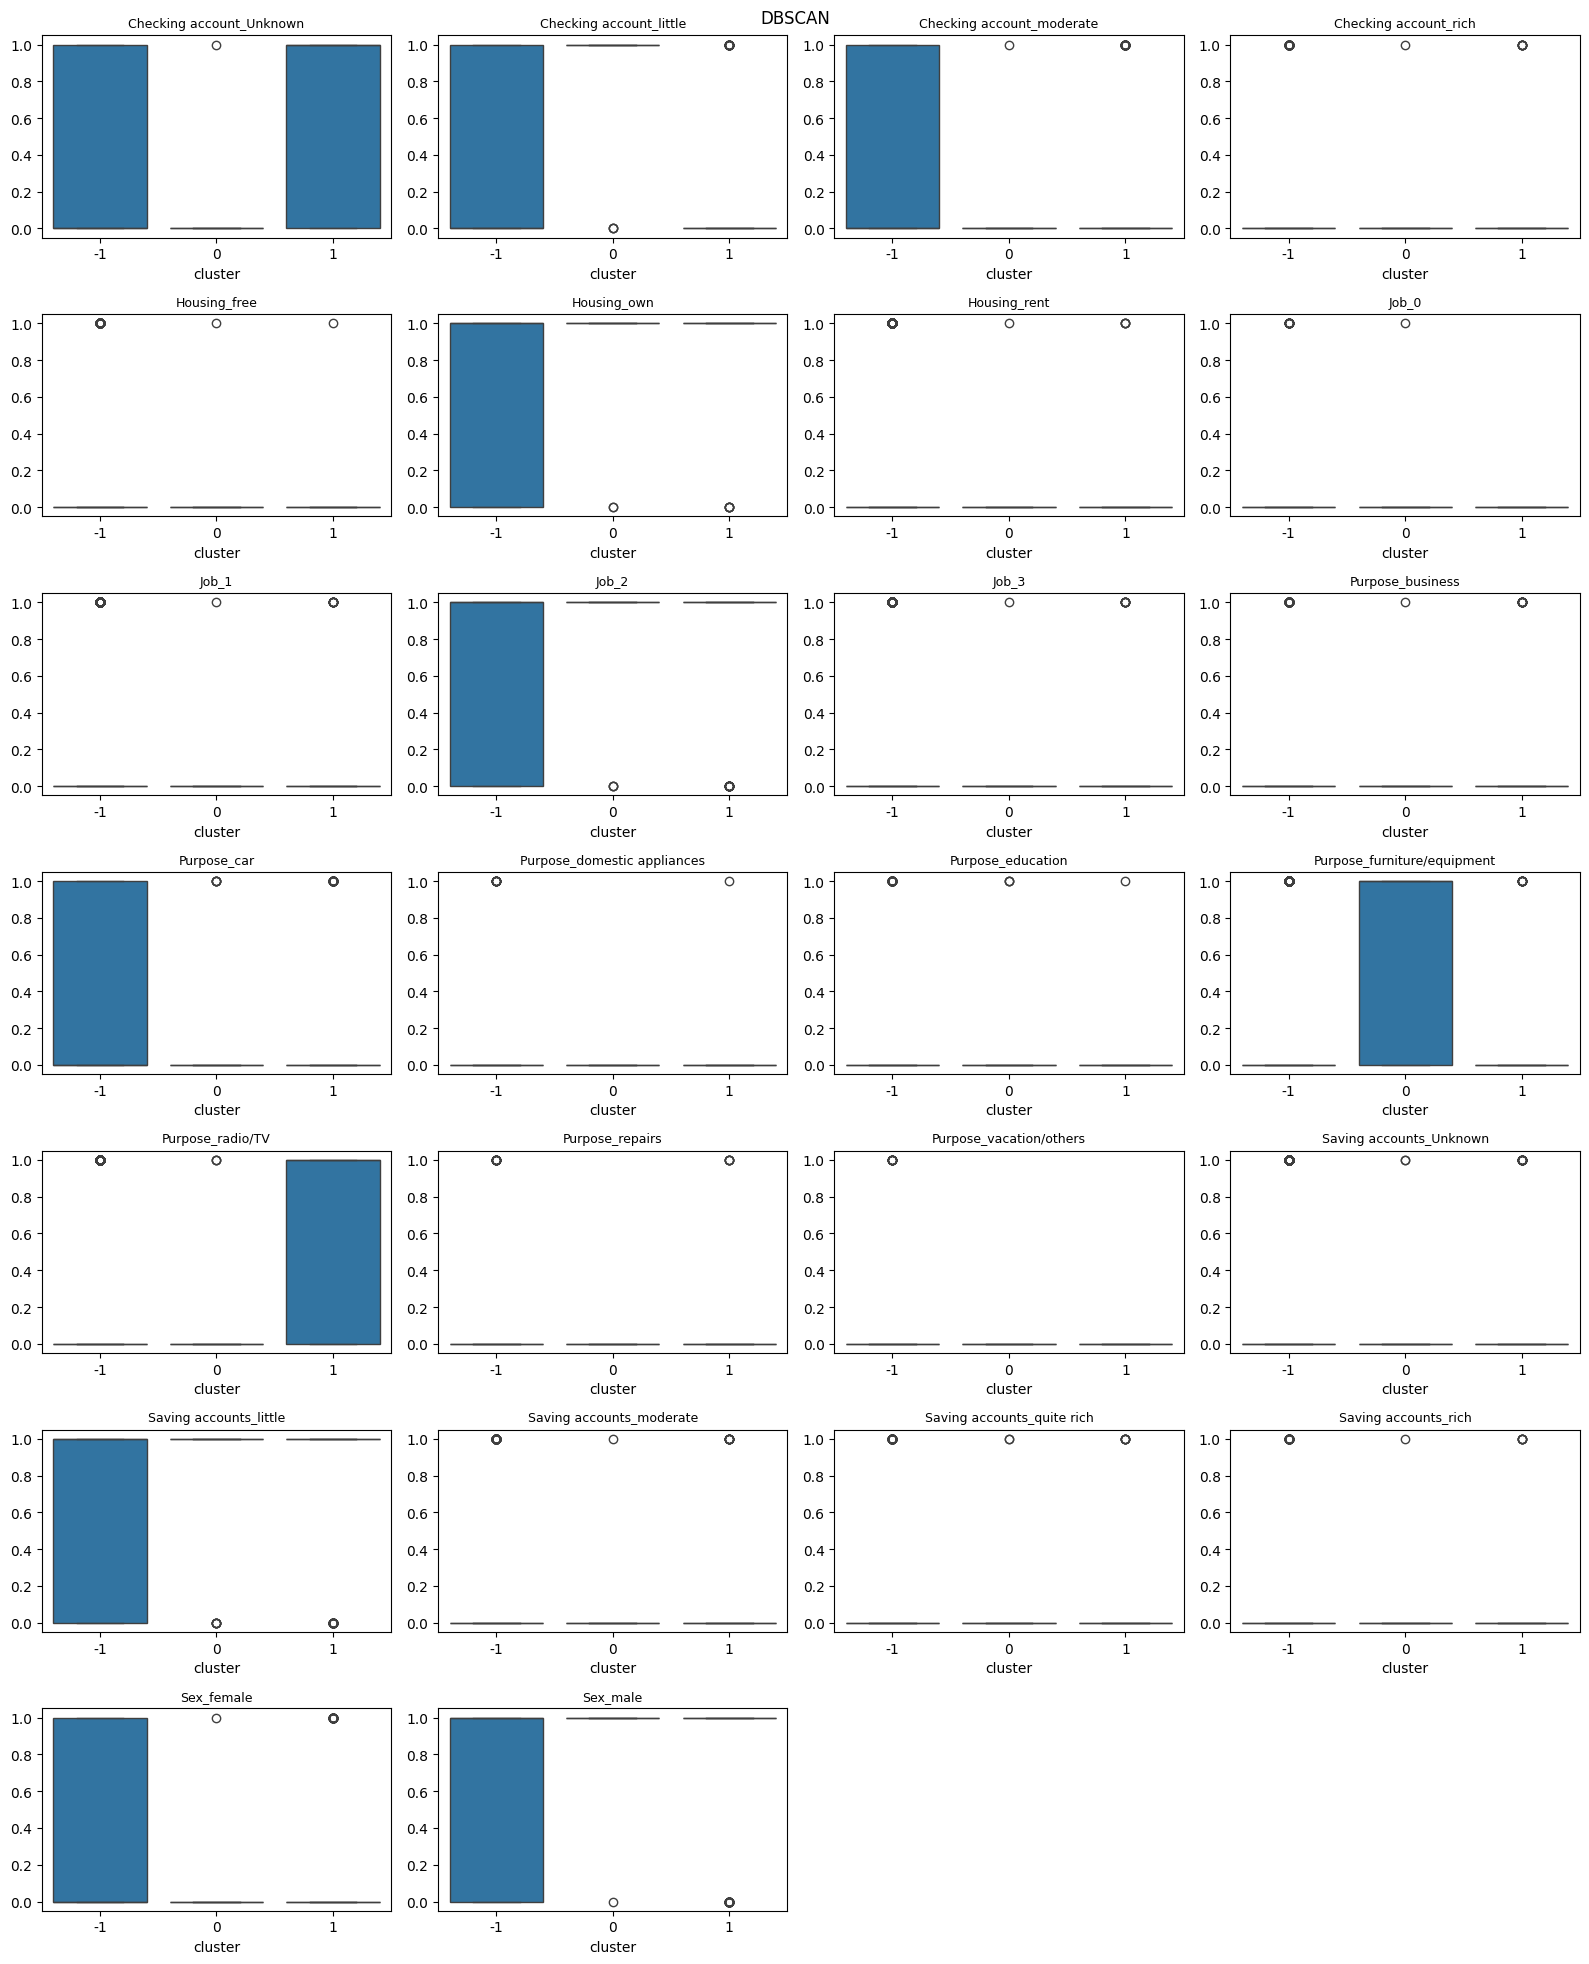

In [32]:
for name, labels in clusters.items():
    grouped = profile.assign(cluster=labels)
    fig, axes = plt.subplots(7, 4, figsize=(16, 20))
    for ax, col in zip(axes.flat, dummy_cols):
        sns.boxplot(data=grouped, x='cluster', y=col, ax=ax)
        ax.set_title(col, fontsize=9)
        ax.set_ylabel('')
    for ax in list(axes.flat)[len(dummy_cols):]:
        ax.axis('off')
    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

## Вывод ##

По silhouette выбраны 2 кластера для k-means (0,200) и 3 кластера для Ward (0,164).
На графиках elbow снижение внутрикластерного разброса замедляется после первых нескольких кластеров.

K-means разделил клиентов на две понятные группы. Кластер 0 — 461 клиент с более крупными и длительными кредитами. Кластер 1 — 539 клиентов с небольшими короткими кредитами. По boxplots сильнее всего различаются сумма и срок кредита.

Ward также выделил группы с крупными длительными и небольшими короткими кредитами, но дополнительно отделил 142 клиента старшего возраста. Здесь заметное различие есть и по возрасту.

DBSCAN при eps=1,3 и min_samples=20 нашёл две группы из 39 и 193 клиентов, но 768 клиентов (76,8%) отнёс к шуму. В первой группе чаще встречаются кредиты на мебель/оборудование, во второй на радио/ТВ. Silhouette равен 0,164 только для нешумовых точек, поэтому напрямую сравнивать его с оценками всей базы нельзя. Для сегментации всех клиентов такой результат не очень удобный.

Для этой задачи лучше отрабатывает k-means: он распределяет всех клиентов и даёт простую сегментацию по размеру и сроку кредита, при этом silhouette невысокий, а распределения пересекаются, поэтому границы групп слабые.  
Оценивать кредитный риск по этим кластерам не получается, целевой переменной риска в данных не нашел.